In [28]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/house-prices-advanced-regression-techniques/sample_submission.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/data_description.txt
/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv


<h1> Exploratory Data Analysis (EDA) - House Prices


# **Introduction**

Phân tích khám phá dữ liệu House Prices theo cấu trúc của tutorial EDA:
- Xác định tính chất dữ liệu
- Phân tích đơn biến
- Phân tích đa biến
- Xác định giá trị thiếu và mẫu bất thường
- Xác định ngoại lệ


EDA được thực hiện bằng các thư viện pandas, matplotlib và seaborn.


In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# **1. Xác định tính chất dữ liệu**


## **Load the dataset**


In [30]:
train = pd.read_csv('/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv')
test = pd.read_csv('/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv')

print("Train shape:", train.shape)
print("Test shape:", test.shape)


Train shape: (1460, 81)
Test shape: (1459, 80)


## **A first look and non-graphical EDA**


In [31]:
train.head()


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [32]:
train.shape


(1460, 81)

### More details: the types of variables


In [33]:
train.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

### Phân loại biến


In [34]:
numeric_cols = train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = train.select_dtypes(include='object').columns.tolist()

print("Biến số:")
print(numeric_cols)

print("\nBiến phân loại:")
print(categorical_cols)

print("\nBiến mục tiêu: SalePrice")


Biến số:
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']

Biến phân loại:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageTy

### **What are the stats of the variables?**


In [35]:
train.describe()


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


# **2. Phân tích đơn biến**


## **Phân phối biến số**


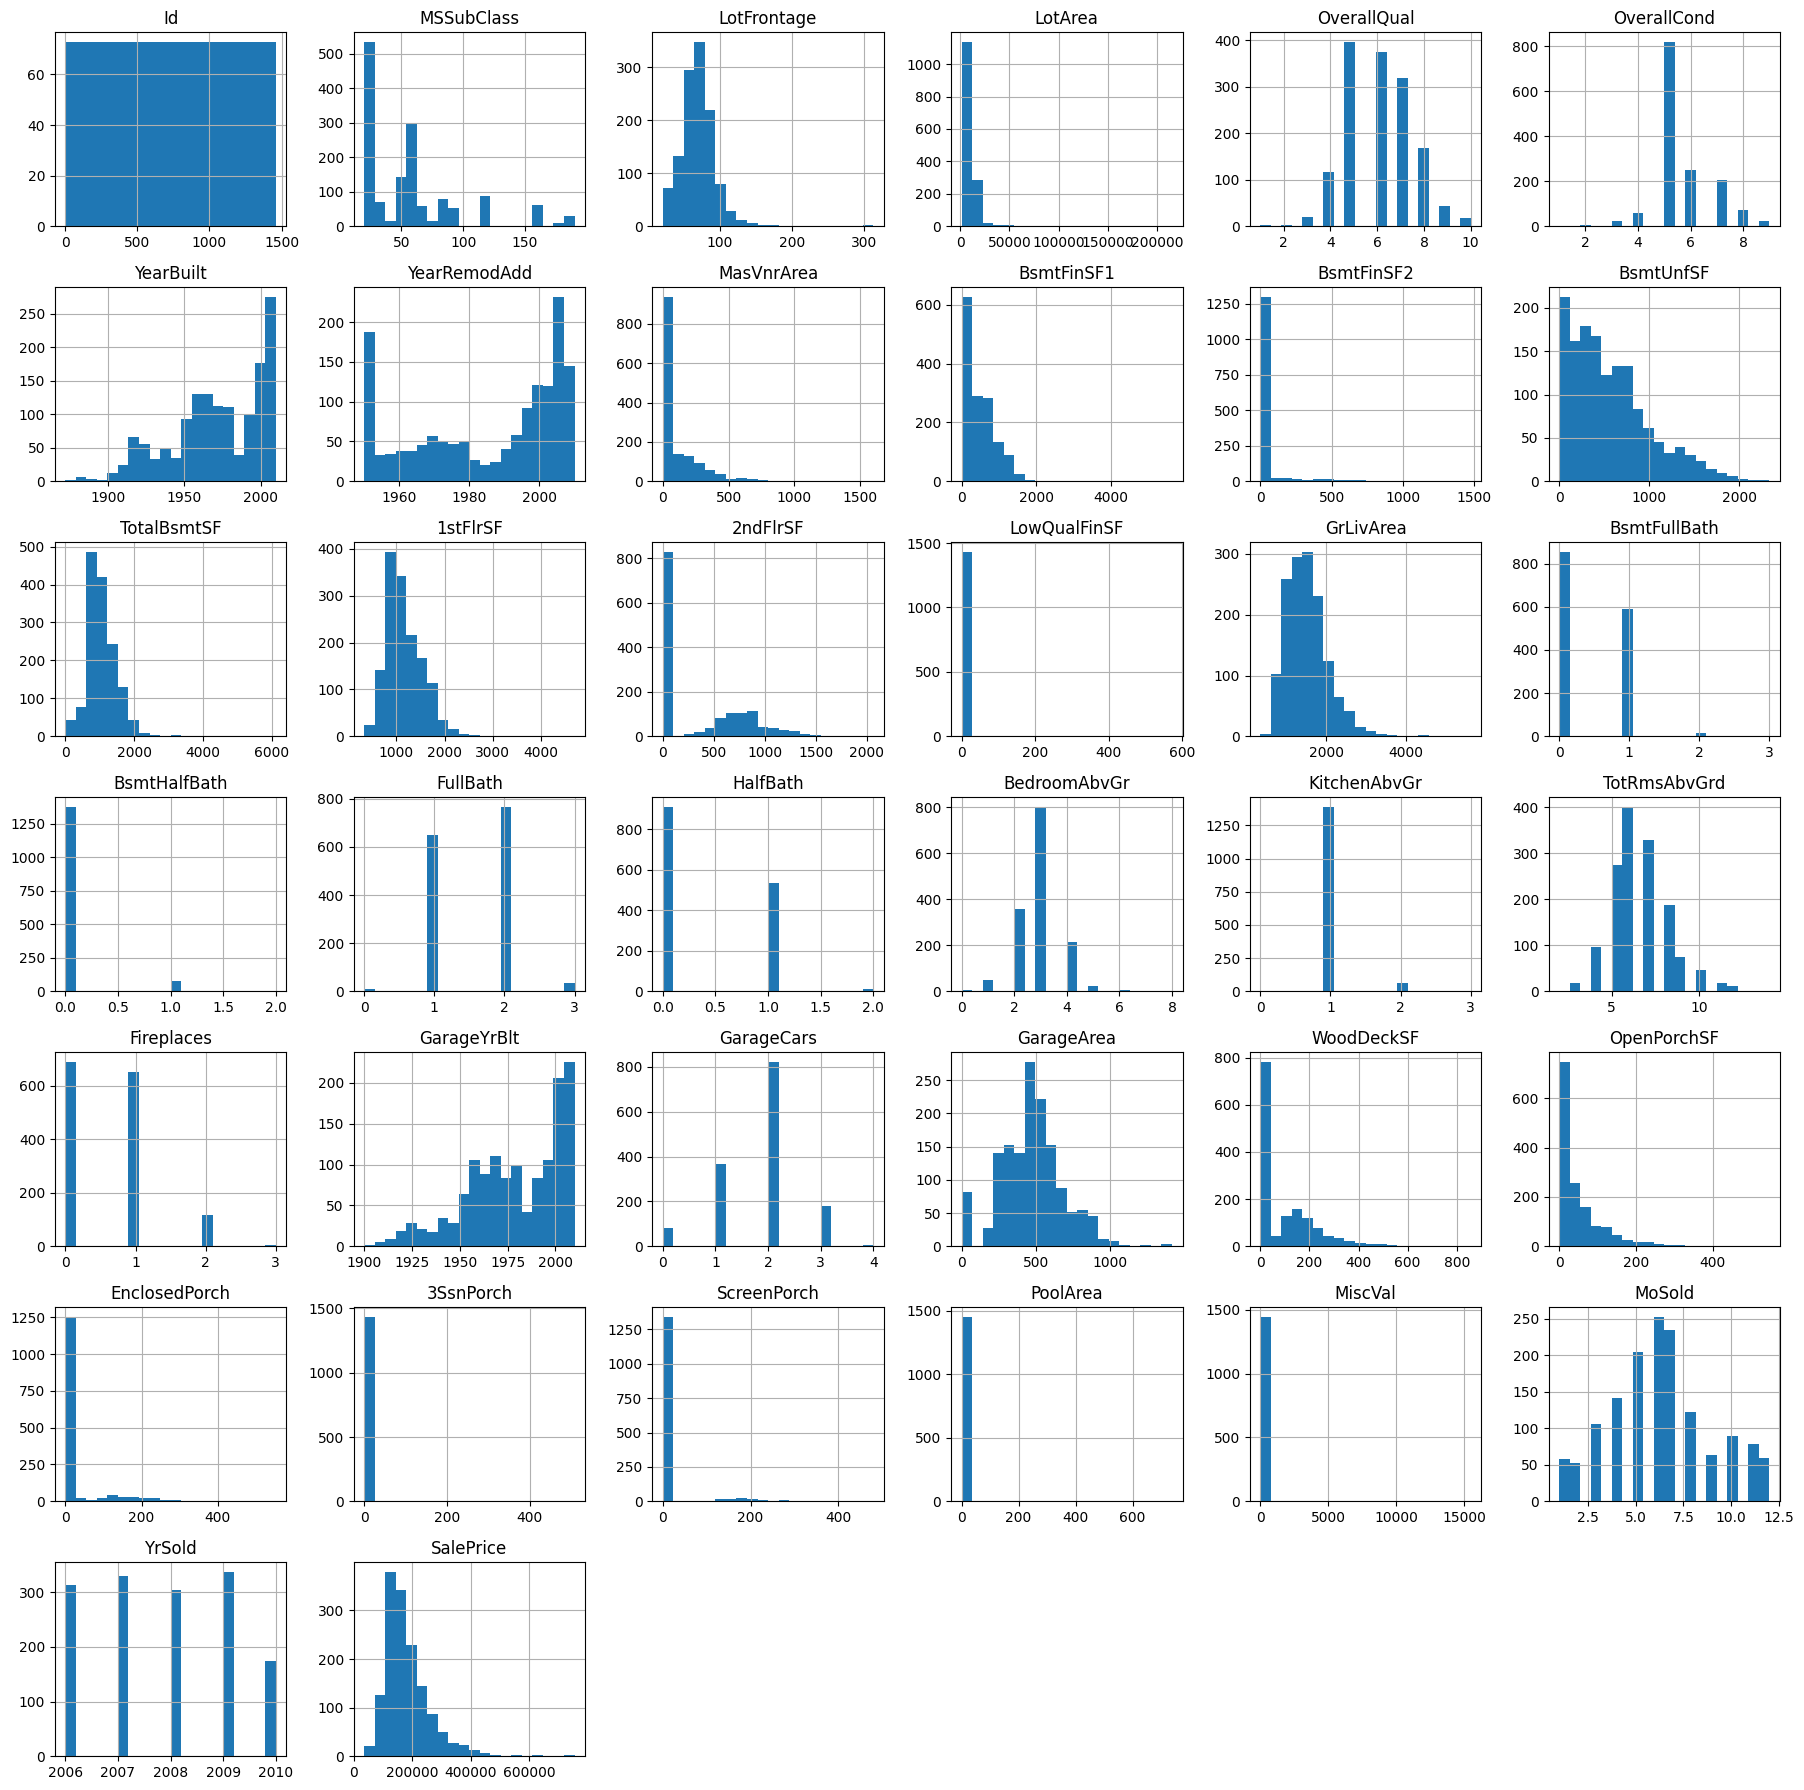

In [36]:
train[numeric_cols].hist(figsize=(18, 18), bins=20)
plt.tight_layout()
plt.show()


### Phân phối SalePrice


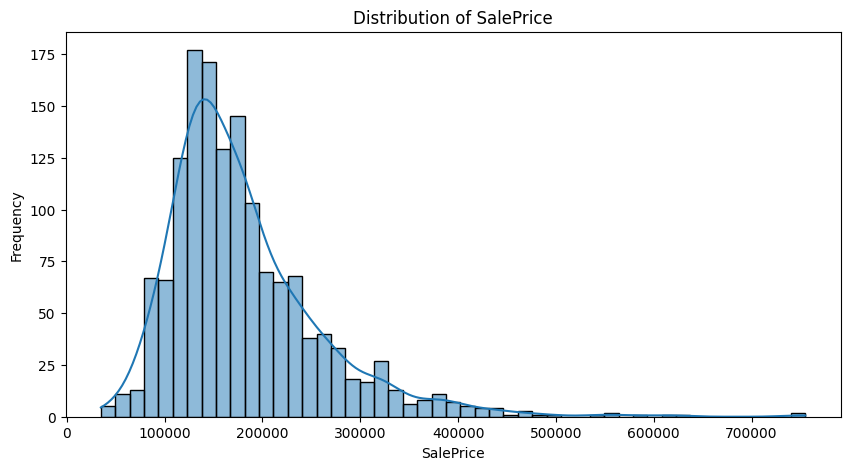

In [37]:
plt.figure(figsize=(10, 5))
sns.histplot(train['SalePrice'], kde=True)
plt.title('Distribution of SalePrice')
plt.xlabel('SalePrice')
plt.ylabel('Frequency')
plt.show()


## **Phân phối biến phân loại**


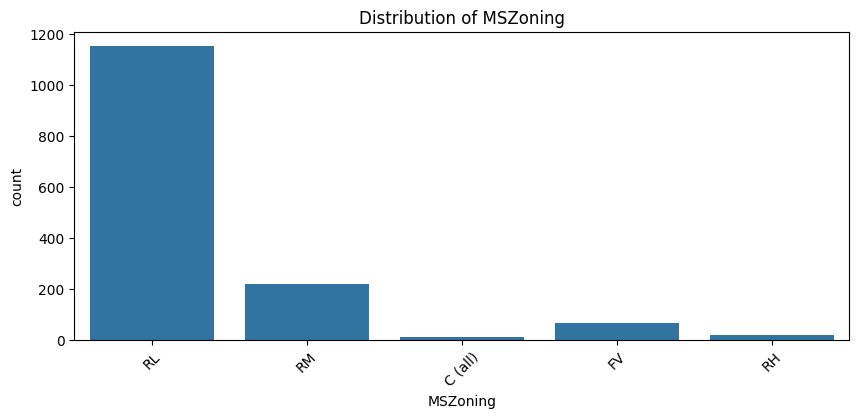

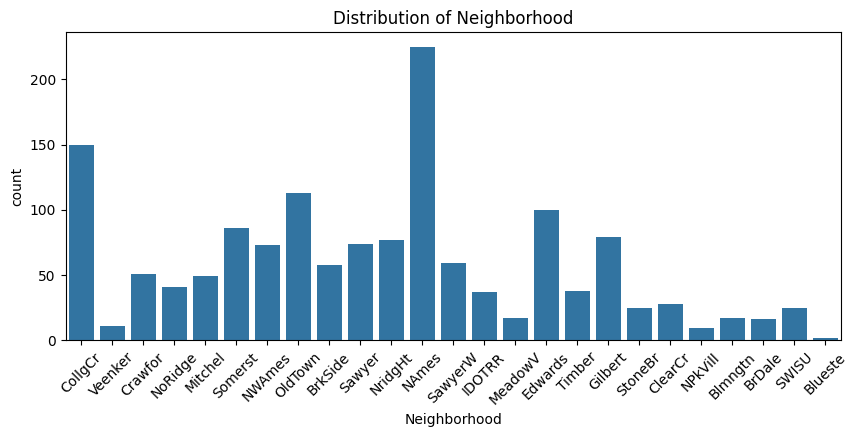

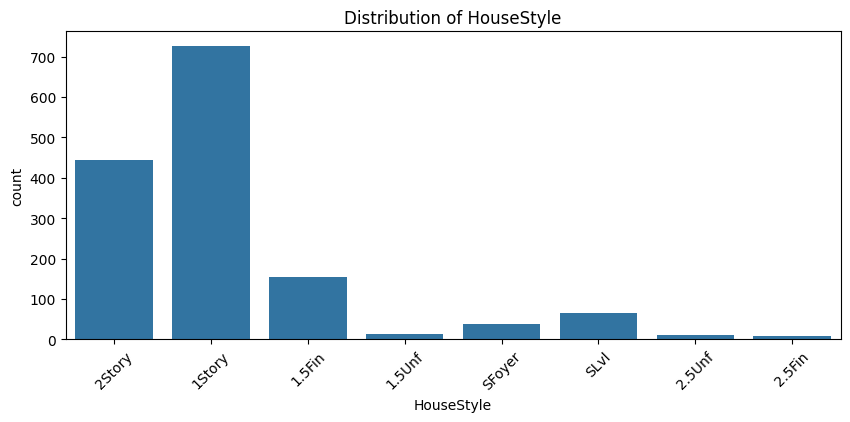

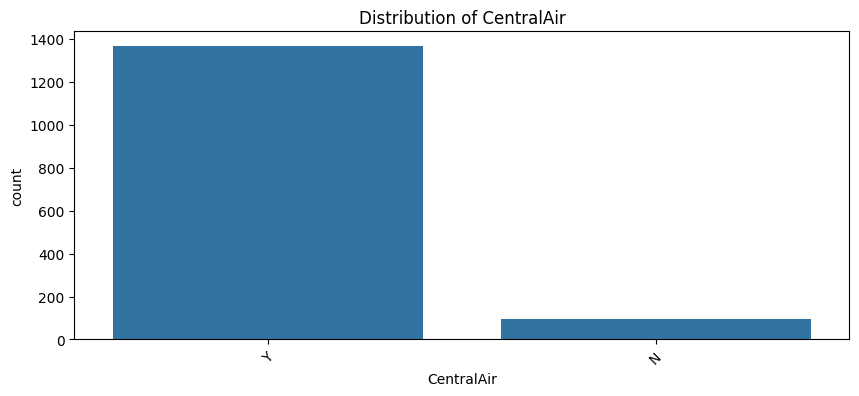

In [38]:
categorical_plot_cols = ['MSZoning', 'Neighborhood', 'HouseStyle', 'CentralAir']

for col in categorical_plot_cols:
    plt.figure(figsize=(10, 4))
    sns.countplot(x=train[col])
    plt.title(f'Distribution of {col}')
    plt.xticks(rotation=45)
    plt.show()


## **Boxplots**


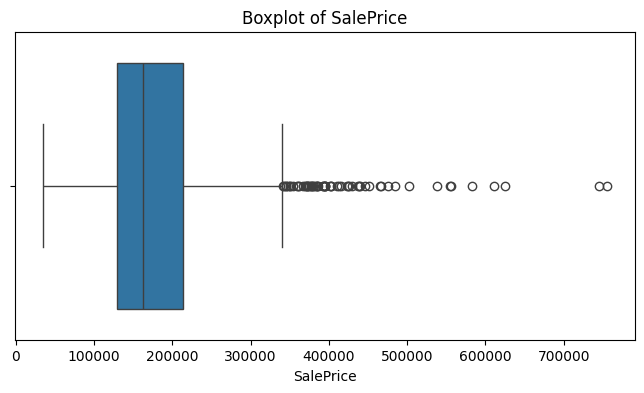

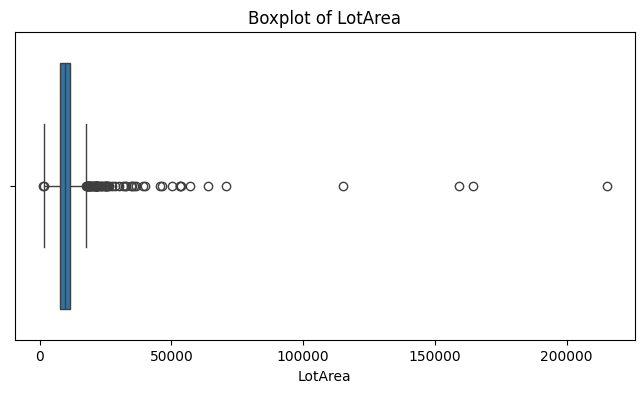

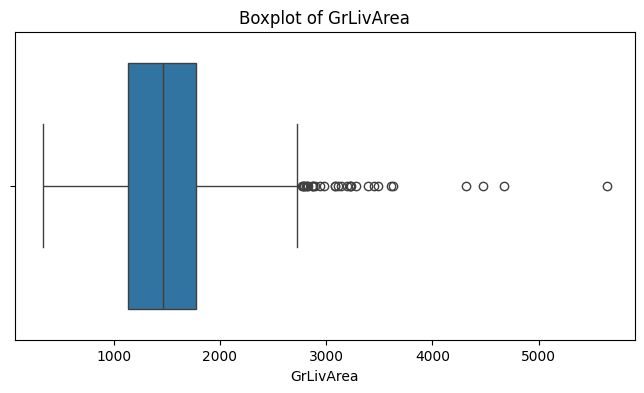

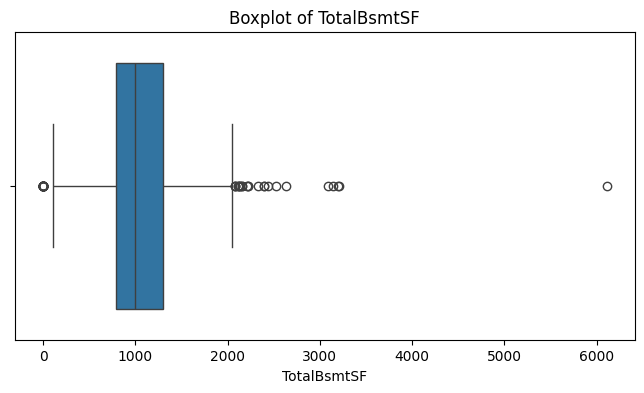

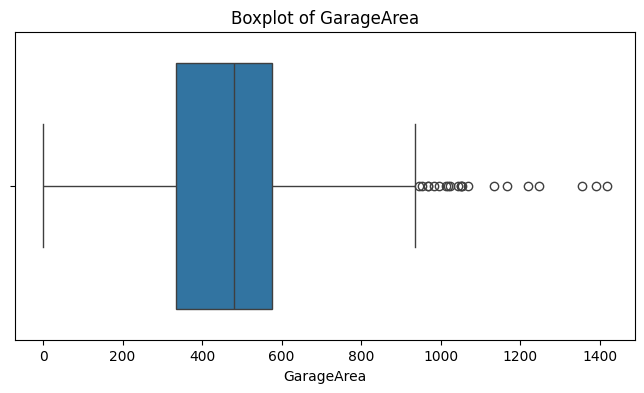

In [39]:
boxplot_cols = ['SalePrice', 'LotArea', 'GrLivArea', 'TotalBsmtSF', 'GarageArea']

for col in boxplot_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=train[col])
    plt.title(f'Boxplot of {col}')
    plt.show()


# **3. Phân tích đa biến**


## **Comparison graphs - Scatterplots**

Scatterplot được sử dụng để quan sát mối quan hệ giữa hai biến.


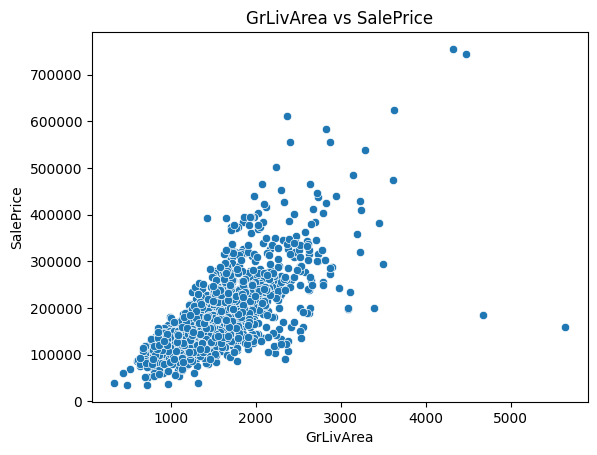

In [40]:
sns.scatterplot(x='GrLivArea', y='SalePrice', data=train)
plt.title('GrLivArea vs SalePrice')
plt.show()


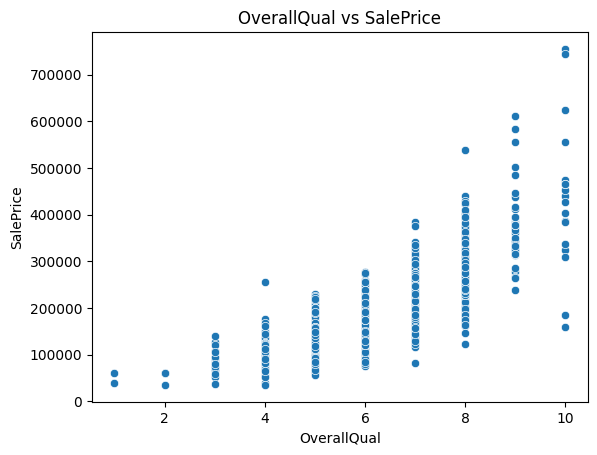

In [41]:
sns.scatterplot(x='OverallQual', y='SalePrice', data=train)
plt.title('OverallQual vs SalePrice')
plt.show()


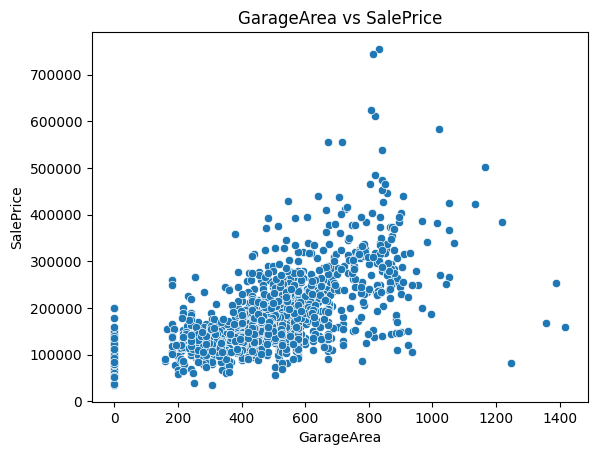

In [42]:
sns.scatterplot(x='GarageArea', y='SalePrice', data=train)
plt.title('GarageArea vs SalePrice')
plt.show()


## **Correlogram**

Correlogram/correlation matrix giúp phân tích mối quan hệ giữa các cặp biến số.


In [43]:
corr = train[numeric_cols].corr()
corr['SalePrice'].sort_values(ascending=False).head(15)


SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Fireplaces      0.466929
BsmtFinSF1      0.386420
Name: SalePrice, dtype: float64

## **Heatmap**


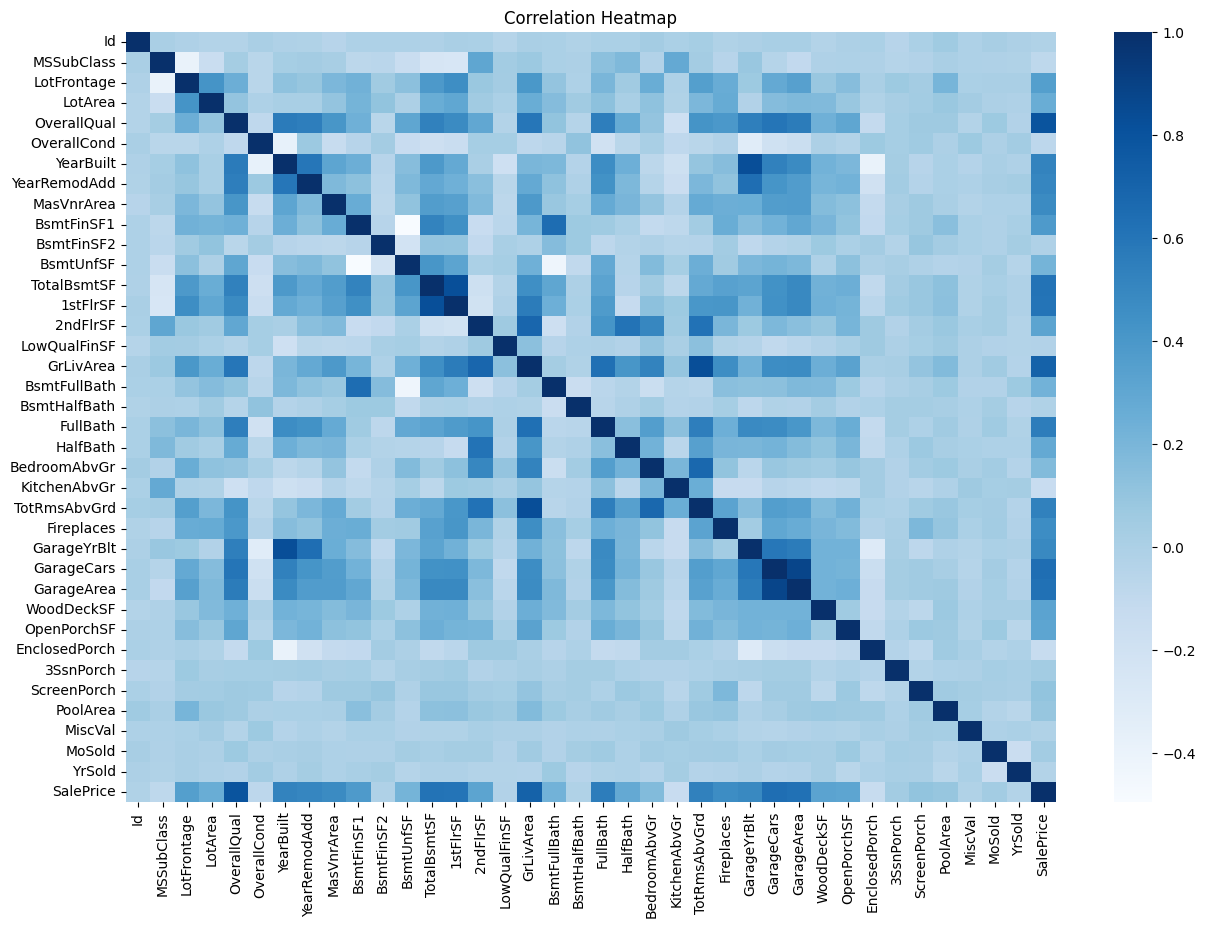

In [44]:
plt.figure(figsize=(15, 10))
sns.heatmap(corr, cmap='Blues', annot=False)
plt.title('Correlation Heatmap')
plt.show()


## **Pairplot**

Quan sát đồng thời mối quan hệ giữa một số biến quan trọng.


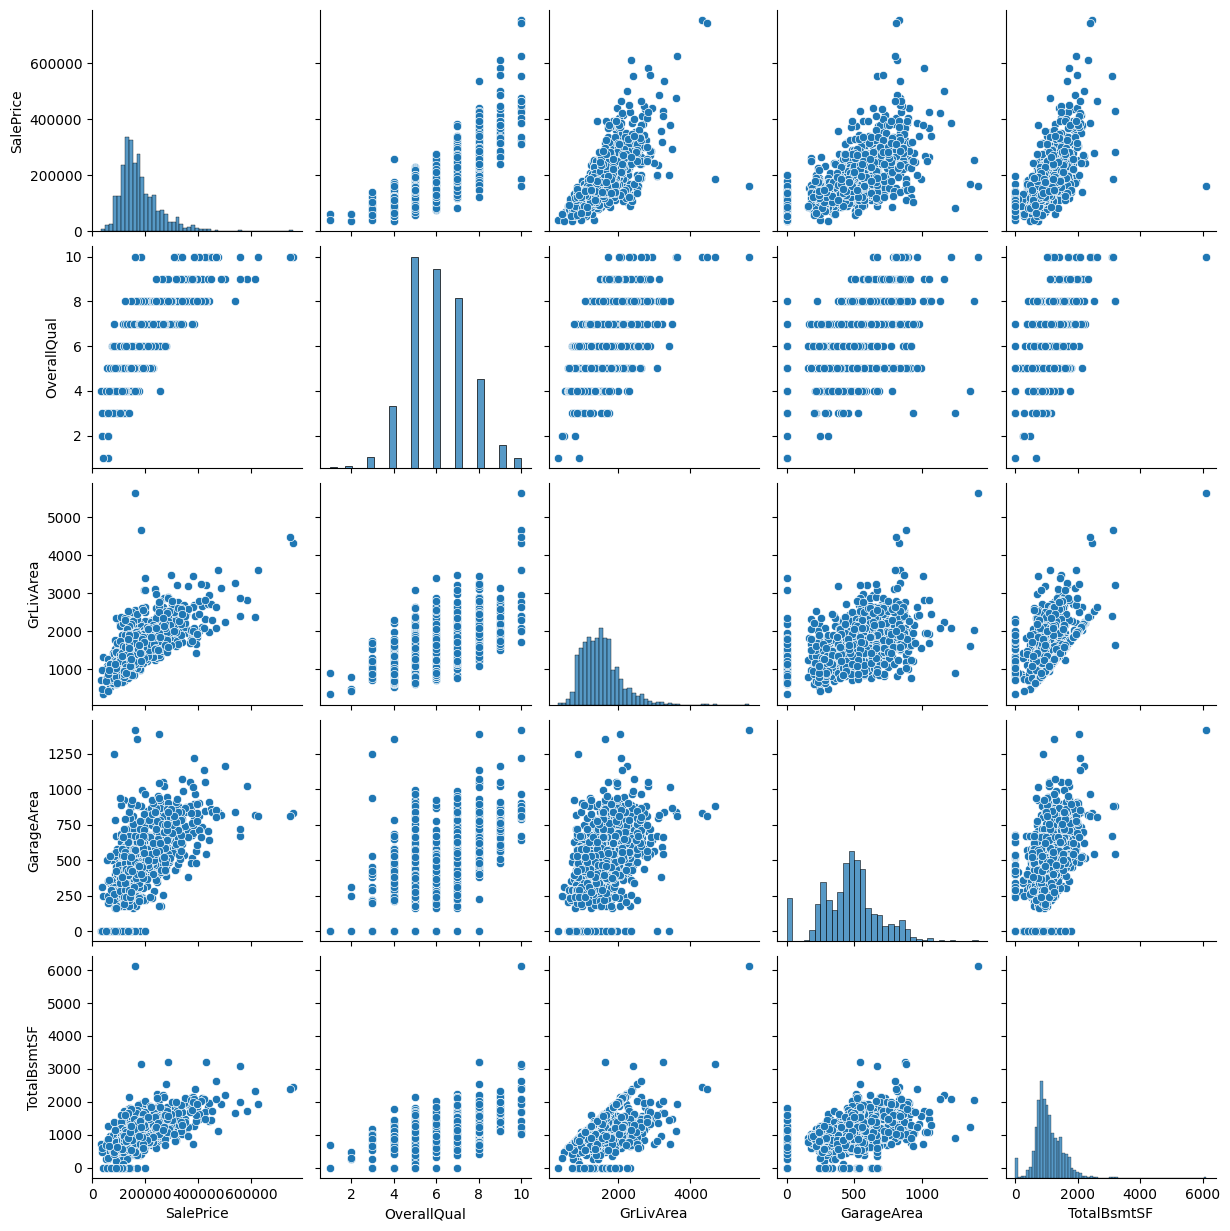

In [45]:
pair_cols = ['SalePrice', 'OverallQual', 'GrLivArea', 'GarageArea', 'TotalBsmtSF']
sns.pairplot(train[pair_cols])
plt.show()


## **Quan hệ giữa biến phân loại và SalePrice**


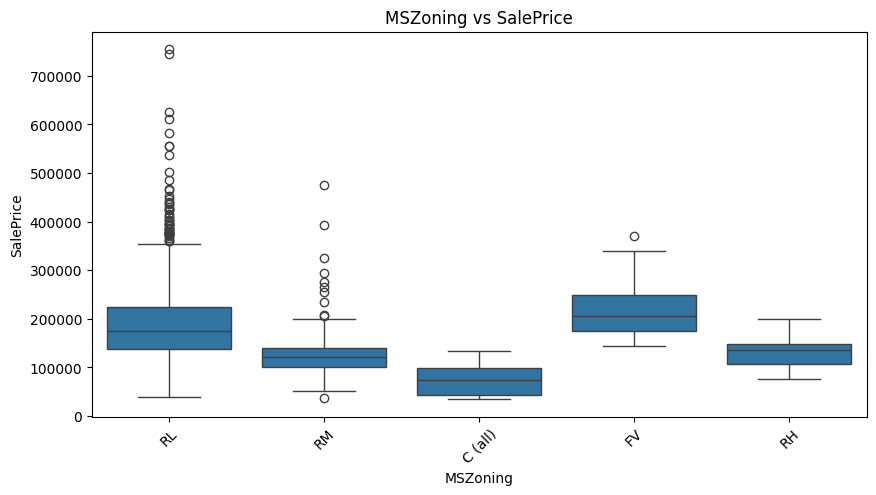

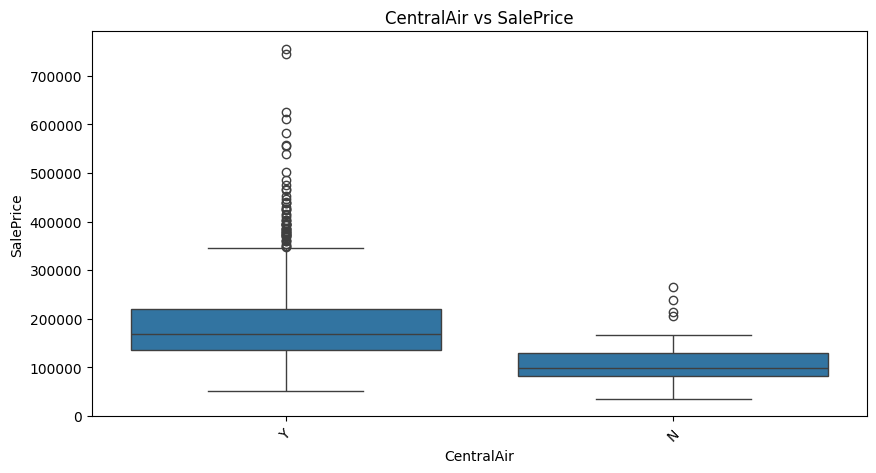

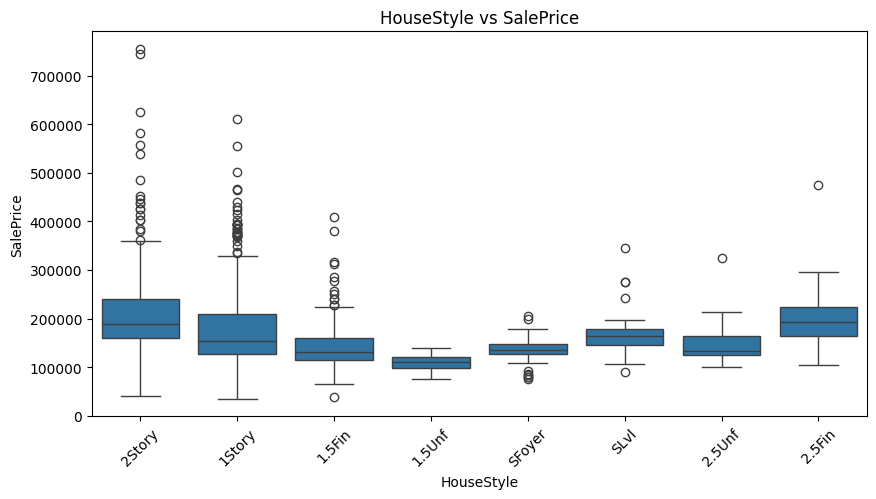

In [46]:
for col in ['MSZoning', 'CentralAir', 'HouseStyle']:
    plt.figure(figsize=(10, 5))
    sns.boxplot(x=col, y='SalePrice', data=train)
    plt.title(f'{col} vs SalePrice')
    plt.xticks(rotation=45)
    plt.show()


# **4. Xác định giá trị thiếu và mẫu bất thường**


## **Check the null/na values**


In [47]:
missing = train.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print("Các biến có giá trị thiếu:")
display(missing)


Các biến có giá trị thiếu:


PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

### Tỷ lệ giá trị thiếu


In [48]:
missing_percent = (train.isnull().mean() * 100).sort_values(ascending=False)
missing_percent = missing_percent[missing_percent > 0]

display(missing_percent.to_frame('Missing (%)'))


,Missing (%)
PoolQC,99.520548
MiscFeature,96.301370
Alley,93.767123
Fence,80.753425
MasVnrType,59.726027
FireplaceQu,47.260274
LotFrontage,17.739726
GarageQual,5.547945
GarageFinish,5.547945
GarageType,5.547945


### Biểu đồ giá trị thiếu


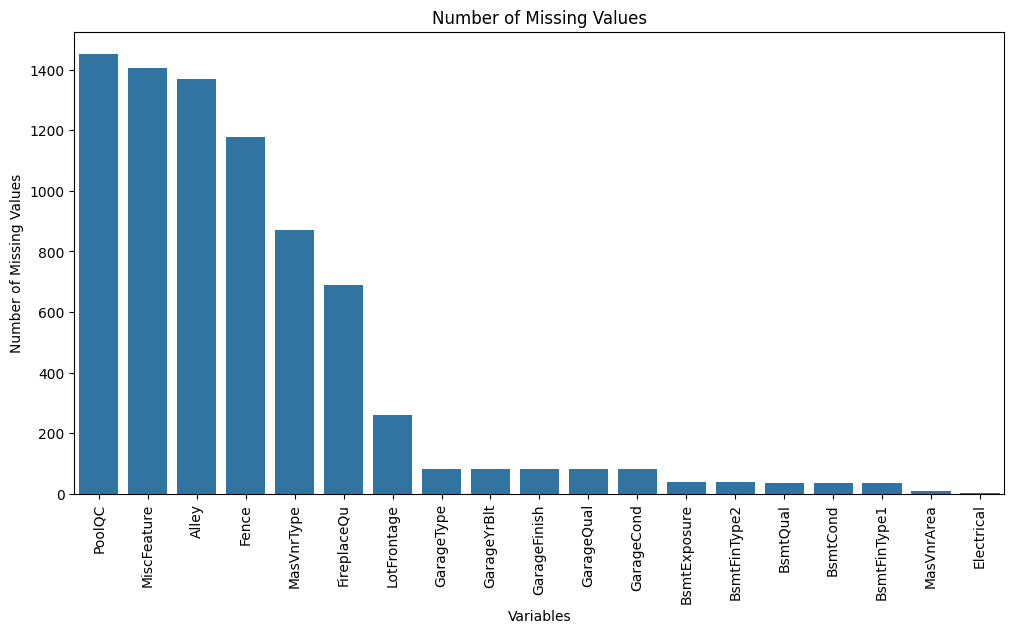

In [49]:
plt.figure(figsize=(12, 6))
sns.barplot(x=missing.index, y=missing.values)
plt.title('Number of Missing Values')
plt.xlabel('Variables')
plt.ylabel('Number of Missing Values')
plt.xticks(rotation=90)
plt.show()


## **Xác định mẫu bất thường**

Kiểm tra một số điều kiện bất hợp lý về mặt dữ liệu.


In [50]:
abnormal = train[
    (train['LotArea'] <= 0) |
    (train['GrLivArea'] <= 0) |
    (train['SalePrice'] <= 0) |
    (train['YearBuilt'] > train['YrSold'])
]

print("Số mẫu bất thường:", len(abnormal))

display(
    abnormal[['Id', 'LotArea', 'GrLivArea', 'YearBuilt', 'YrSold', 'SalePrice']]
)


Số mẫu bất thường: 0


,Id,LotArea,GrLivArea,YearBuilt,YrSold,SalePrice


### Kiểm tra từng điều kiện bất thường


In [51]:
print("LotArea <= 0:", (train['LotArea'] <= 0).sum())
print("GrLivArea <= 0:", (train['GrLivArea'] <= 0).sum())
print("SalePrice <= 0:", (train['SalePrice'] <= 0).sum())
print("YearBuilt > YrSold:", (train['YearBuilt'] > train['YrSold']).sum())


LotArea <= 0: 0
GrLivArea <= 0: 0
SalePrice <= 0: 0
YearBuilt > YrSold: 0


# **5. Xác định ngoại lệ**


## **Boxplots và IQR**

Sử dụng phương pháp IQR để xác định các giá trị nằm ngoài khoảng:

**Lower bound = Q1 - 1.5 × IQR**

**Upper bound = Q3 + 1.5 × IQR**


In [52]:
outlier_cols = ['SalePrice', 'LotArea', 'GrLivArea', 'TotalBsmtSF', 'GarageArea']

outlier_summary = []

for col in outlier_cols:
    Q1 = train[col].quantile(0.25)
    Q3 = train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    mask = (train[col] < lower) | (train[col] > upper)

    outlier_summary.append({
        'Variable': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower,
        'Upper Bound': upper,
        'Number of Outliers': mask.sum(),
        'Percentage (%)': mask.mean() * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)
display(outlier_summary)


,Variable,Q1,Q3,IQR,Lower Bound,Upper Bound,Number of Outliers,Percentage (%)
0,SalePrice,129975.00,214000.00,84025.00,3937.500,340037.500,61,4.178082
1,LotArea,7553.50,11601.50,4048.00,1481.500,17673.500,69,4.726027
2,GrLivArea,1129.50,1776.75,647.25,158.625,2747.625,31,2.123288
3,TotalBsmtSF,795.75,1298.25,502.50,42.000,2052.000,61,4.178082
4,GarageArea,334.50,576.00,241.50,-27.750,938.250,21,1.438356


### Trực quan hóa ngoại lệ bằng Boxplot


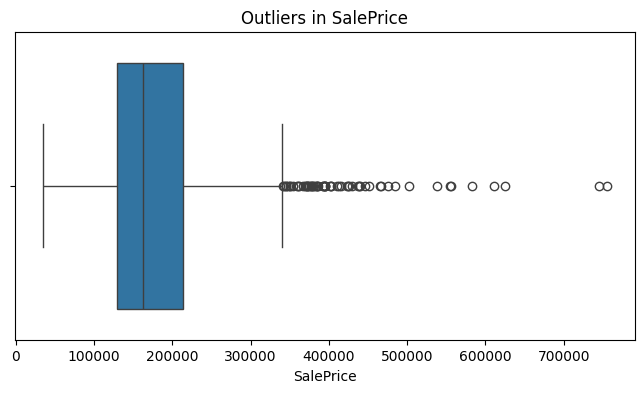

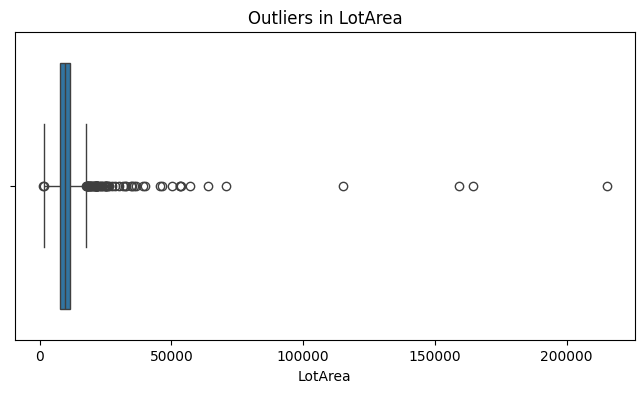

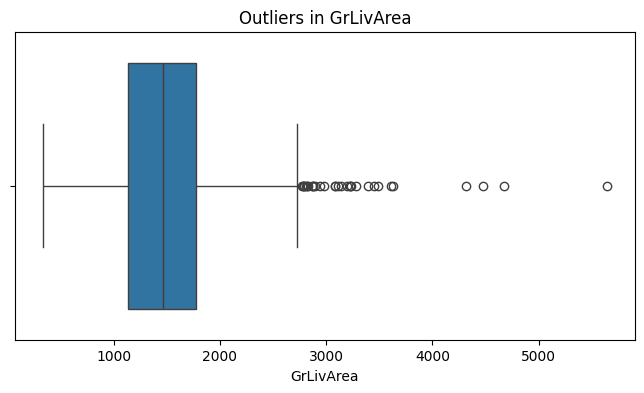

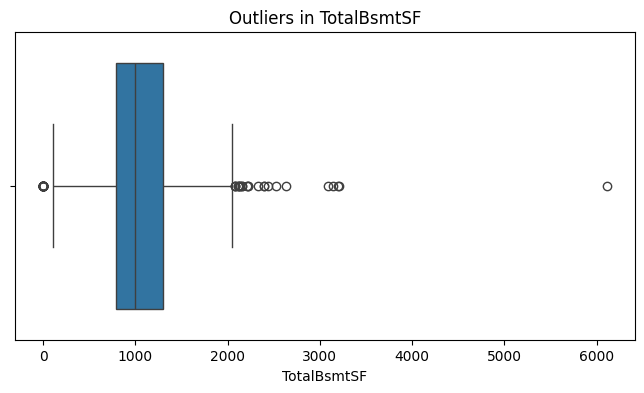

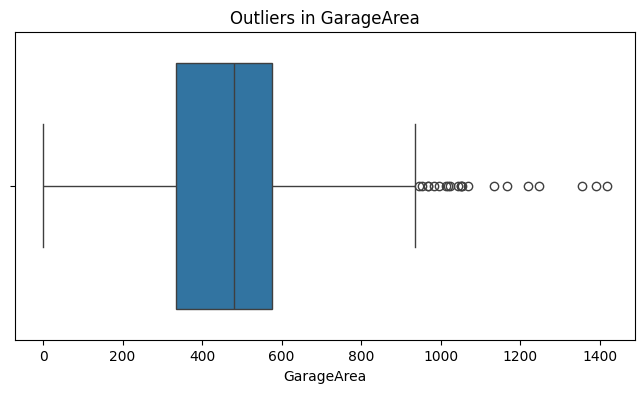

In [53]:
for col in outlier_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=train[col])
    plt.title(f'Outliers in {col}')
    plt.show()


### Danh sách các mẫu ngoại lệ


In [56]:
for col in ['SalePrice', 'GrLivArea', 'LotArea']:

    Q1 = train[col].quantile(0.25)
    Q3 = train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = train[(train[col] < lower) | (train[col] > upper)].copy()

    print(f'\n{col}: {len(outliers)} mẫu ngoại lệ')

    if col == 'SalePrice':
        display(outliers[['Id', 'SalePrice']].sort_values(by='SalePrice'))
    else:
        display(outliers[['Id', col, 'SalePrice']].sort_values(by=col))


SalePrice: 61 mẫu ngoại lệ


,Id,SalePrice
718,719,341000
320,321,342643
642,643,345000
11,12,345000
990,991,348000
...,...,...
803,804,582933
898,899,611657
1169,1170,625000
1182,1183,745000



GrLivArea: 31 mẫu ngoại lệ


,Id,GrLivArea,SalePrice
583,584,2775,325000
1386,1387,2784,250000
1328,1329,2792,256000
231,232,2794,403000
1312,1313,2810,302000
803,804,2822,582933
1142,1143,2828,424870
1046,1047,2868,556581
1175,1176,2872,285000
961,962,2872,272000



LotArea: 69 mẫu ngoại lệ


,Id,LotArea,SalePrice
956,957,1300,124000
1039,1040,1477,80000
1151,1152,17755,149900
1277,1278,17871,197900
854,855,17920,170000
...,...,...,...
451,452,70761,280000
706,707,115149,302000
249,250,159000,277000
335,336,164660,228950
